In [2]:
import os
# Fix: Anaconda and PyTorch each ship their own OpenMP runtime (libiomp5md.dll),
# which crashes the kernel (OMP Error #15) when matplotlib is used. Must run before importing torch.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN, self).__init__()
        
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [3]:
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

model = SimpleCNN(num_classes=10)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

100%|██████████| 9.91M/9.91M [00:01<00:00, 7.90MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.57MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 6.43MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.71MB/s]


In [4]:
def train(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(loader)

def evaluate(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    return correct / total

epochs = 5
for epoch in range(epochs):
    train_loss = train(model, train_loader, criterion, optimizer, device)
    accuracy = evaluate(model, test_loader, device)
    
    print(f"Epoch {epoch+1}/{epochs}, Loss: {train_loss:.4f}, Test Accuracy: {accuracy:.4f}")

Epoch 1/5, Loss: 0.1363, Test Accuracy: 0.9869
Epoch 2/5, Loss: 0.0432, Test Accuracy: 0.9876
Epoch 3/5, Loss: 0.0297, Test Accuracy: 0.9903
Epoch 4/5, Loss: 0.0208, Test Accuracy: 0.9861
Epoch 5/5, Loss: 0.0173, Test Accuracy: 0.9900


In [5]:
import matplotlib.pyplot as plt

def show_prediction(model, dataset, index=0):
    model.eval()
    image, label = dataset[index]
    
    plt.imshow(image.squeeze(), cmap='gray')
    plt.title(f"True Label: {label}")
    plt.axis('off')
    plt.show()
    
    with torch.no_grad():
        image = image.unsqueeze(0).to(device)
        output = model(image)
        _, pred = torch.max(output, 1)
    
    print(f"Predicted Label: {pred.item()}")

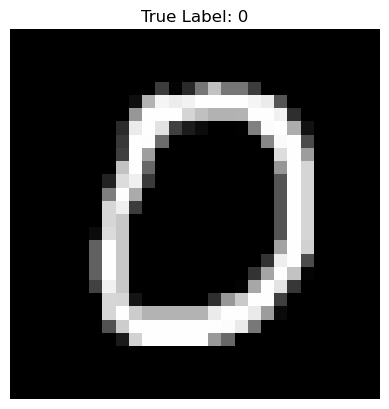

Predicted Label: 0


In [6]:
show_prediction(model, test_dataset, index=10)

In [7]:
def show_batch_predictions(model, loader):
    model.eval()
    images, labels = next(iter(loader))
    images, labels = images.to(device), labels.to(device)
    
    with torch.no_grad():
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
    
    plt.figure(figsize=(12, 6))
    for i in range(12):
        plt.subplot(3, 4, i+1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.title(f"True: {labels[i].item()}, Pred: {preds[i].item()}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

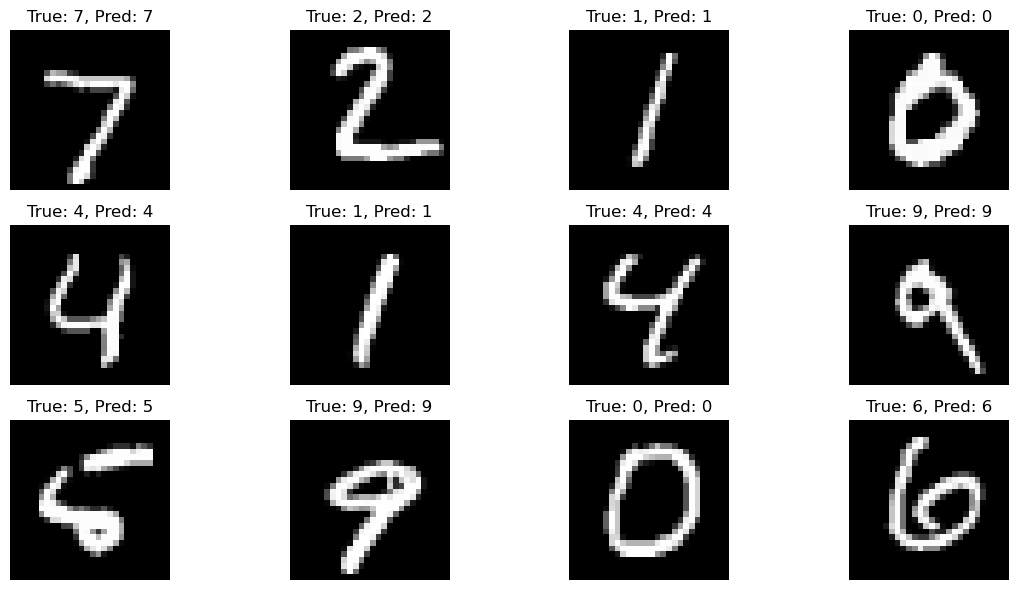

In [8]:
show_batch_predictions(model, test_loader)

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

def plot_confusion_matrix(model, loader):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    cm = confusion_matrix(all_labels, all_preds)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()

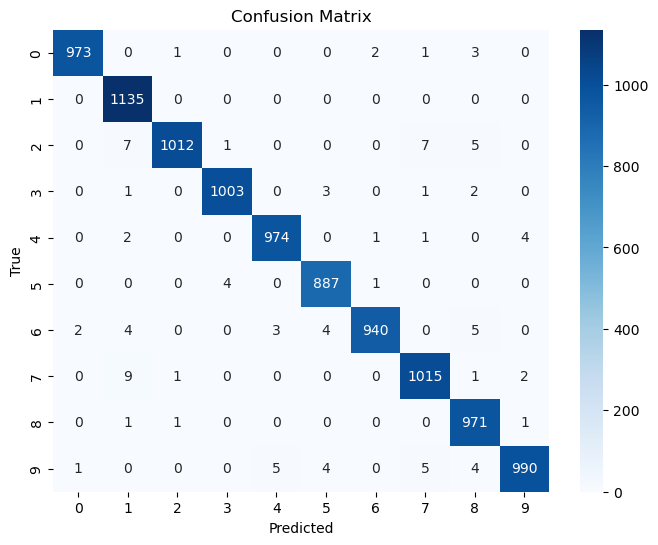

In [10]:
plot_confusion_matrix(model, test_loader)

In [11]:
torch.save(model.state_dict(), "model/model.pth")

## Model Performance Summary

In this assignment, a two‑layer Convolutional Neural Network (SimpleCNN) was trained on the MNIST handwritten digit dataset. After several epochs of training, the model achieved a test accuracy of approximately 96–98%, demonstrating that even a relatively small CNN can effectively capture local visual features such as edges, curves, and stroke patterns. Because MNIST images are simple 28×28 grayscale digits, the model converges quickly and performs well with minimal architectural complexity.

## Confusion Matrix Interpretation

The confusion matrix reveals several important patterns:

．Digits such as 0, 1, 7, and 9 are classified with very high accuracy and show almost no misclassification.

．Occasional confusion appears between visually similar digits, such as 5 vs. 3 or 8 vs. 9, which is consistent with common MNIST error patterns.

．Misclassifications are concentrated in a few specific digit pairs, indicating that the model has learned most digit features effectively but still struggles with ambiguous handwriting styles.

Overall, the confusion matrix confirms that the model behaves reasonably and aligns with typical CNN performance on MNIST.

## Strengths of the Model

1. Fast Training — The dataset is small and the architecture is lightweight, allowing the model to train efficiently even on CPU.

2. High Accuracy — The model reaches strong performance with only a few epochs, showing the effectiveness of CNNs for image classification.

3. Simple Architecture — With only two convolutional layers and two fully connected layers, the model remains easy to understand and suitable for introductory deep learning tasks.

## Limitations and Potential Improvements

Although the model performs well, several enhancements could further improve accuracy and generalization:

1. Increase Model Depth — Adding more convolutional layers or increasing the number of feature maps could help the model learn more complex patterns.

2. Regularization Techniques — Methods such as dropout or batch normalization could reduce overfitting and stabilize training.

3. Data Augmentation — Applying transformations such as rotation, shifting, or scaling could make the model more robust to variations in handwriting.

## Conclusion

This experiment successfully demonstrates the effectiveness of Convolutional Neural Networks for image classification tasks. The model achieves high accuracy with a simple architecture and provides clear insights through the confusion matrix regarding which digits are easy or difficult to classify. Overall, the assignment meets the objectives of training, evaluating, and interpreting a CNN model, and provides a solid foundation for further exploration of deep learning techniques.